# Exploratory Data Analysis of Air Quality in Indian Cities

## Research Topic

**When Air Quality Models Fail: Robustness of Machine Learning Predictions During Extreme Pollution Events in Indian Cities**

## Research Question

Do machine-learning models remain reliable during extreme pollution episodes, or does their prediction performance degrade when AQI becomes severe?

## Objective

This study aims to explore and analyze air-quality data from Indian cities before applying Machine Learning and Deep Learning models, with special focus on extreme pollution episodes.

In [1]:
# ==========================================
#  IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ==========================================
#  LOAD DATASET
# ==========================================

file_path = r"C:\Users\baris\OneDrive\Desktop\Air_Quality_Research\dataset\INDIA_AQI_COMPLETE_20251126.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# ==========================================
#  DATASET PREVIEW
# ==========================================

df.head()

,City,State,Latitude,Longitude,Datetime,Year,Month,Day,Hour,Day_of_Week,...,US_AQI_CO,EU_AQI,EU_AQI_PM25,EU_AQI_PM10,AQI_Category,PM25_Category_India,Temp_Inversion,Inversion_Strength_C,Festival_Period,Crop_Burning_Season
0,Agartala,Tripura,23.8315,91.2868,2022-08-05 00:00:00,2022,8,5,0,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
1,Agartala,Tripura,23.8315,91.2868,2022-08-05 01:00:00,2022,8,5,1,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
2,Agartala,Tripura,23.8315,91.2868,2022-08-05 02:00:00,2022,8,5,2,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
3,Agartala,Tripura,23.8315,91.2868,2022-08-05 03:00:00,2022,8,5,3,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
4,Agartala,Tripura,23.8315,91.2868,2022-08-05 04:00:00,2022,8,5,4,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0


In [4]:
df.tail()

,City,State,Latitude,Longitude,Datetime,Year,Month,Day,Hour,Day_of_Week,...,US_AQI_CO,EU_AQI,EU_AQI_PM25,EU_AQI_PM10,AQI_Category,PM25_Category_India,Temp_Inversion,Inversion_Strength_C,Festival_Period,Crop_Burning_Season
842155,Visakhapatnam,Andhra Pradesh,17.6868,83.2185,2025-11-26 19:00:00,2025,11,26,19,2,...,9,118.0,118.0,81.0,Unhealthy,Moderate,0,NaN,0,1
842156,Visakhapatnam,Andhra Pradesh,17.6868,83.2185,2025-11-26 20:00:00,2025,11,26,20,2,...,9,117.0,117.0,80.0,Unhealthy,Moderate,0,NaN,0,1
842157,Visakhapatnam,Andhra Pradesh,17.6868,83.2185,2025-11-26 21:00:00,2025,11,26,21,2,...,10,116.0,116.0,80.0,Unhealthy,Moderate,0,NaN,0,1
842158,Visakhapatnam,Andhra Pradesh,17.6868,83.2185,2025-11-26 22:00:00,2025,11,26,22,2,...,10,115.0,115.0,79.0,Unhealthy,Moderate,0,NaN,0,1
842159,Visakhapatnam,Andhra Pradesh,17.6868,83.2185,2025-11-26 23:00:00,2025,11,26,23,2,...,11,114.0,114.0,79.0,Unhealthy,Moderate,0,NaN,0,1


In [5]:
# ==========================================
#  DATASET SHAPE
# ==========================================

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 842160
Number of Columns: 71


In [6]:
# ==========================================
#  COLUMN NAMES
# ==========================================

print("Total Number of Columns:", len(df.columns))
print("\nColumn Names:\n")

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Total Number of Columns: 71

Column Names:

1. City
2. State
3. Latitude
4. Longitude
5. Datetime
6. Year
7. Month
8. Day
9. Hour
10. Day_of_Week
11. Day_Name
12. Week_of_Year
13. Is_Weekend
14. Quarter
15. Season
16. Time_of_Day
17. Temp_2m_C
18. Temp_80m_C
19. Temp_120m_C
20. Temp_180m_C
21. Humidity_Percent
22. Dew_Point_C
23. Humidity_Category
24. Wind_Speed_10m_kmh
25. Wind_Speed_80m_kmh
26. Wind_Speed_120m_kmh
27. Wind_Dir_10m
28. Wind_Gusts_kmh
29. Wind_Category
30. Wind_Stagnation
31. Precipitation_mm
32. Rain_mm
33. Is_Raining
34. Heavy_Rain
35. Pressure_MSL_hPa
36. Surface_Pressure_hPa
37. Solar_Radiation_Wm2
38. Direct_Radiation_Wm2
39. Diffuse_Radiation_Wm2
40. UV_Index
41. Cloud_Cover_Percent
42. Cloud_Low_Percent
43. Cloud_Mid_Percent
44. Cloud_High_Percent
45. Is_Daytime
46. Sunshine_Seconds
47. PM2_5_ugm3
48. PM10_ugm3
49. PM_Ratio
50. CO_ugm3
51. NO2_ugm3
52. SO2_ugm3
53. O3_ugm3
54. Dust_ugm3
55. NH3_ugm3
56. AOD
57. US_AQI
58. US_AQI_PM25
59. US_AQI_PM10
60. US_AQI_N

In [7]:
# ==========================================
#  DATASET INFORMATION
# ==========================================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 842160 entries, 0 to 842159
Data columns (total 71 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   City                   842160 non-null  object 
 1   State                  842160 non-null  object 
 2   Latitude               842160 non-null  float64
 3   Longitude              842160 non-null  float64
 4   Datetime               842160 non-null  object 
 5   Year                   842160 non-null  int64  
 6   Month                  842160 non-null  int64  
 7   Day                    842160 non-null  int64  
 8   Hour                   842160 non-null  int64  
 9   Day_of_Week            842160 non-null  int64  
 10  Day_Name               842160 non-null  object 
 11  Week_of_Year           842160 non-null  int64  
 12  Is_Weekend             842160 non-null  int64  
 13  Quarter                842160 non-null  int64  
 14  Season                 842160 non-nu

In [8]:
# ==========================================
#  MISSING VALUES ANALYSIS
# ==========================================

missing_count = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_count[missing_count > 0])

Missing Values in Each Column:
Temp_80m_C              842160
Temp_120m_C             842160
Temp_180m_C             842160
Wind_Speed_80m_kmh      842160
Wind_Speed_120m_kmh     842160
UV_Index                842160
NH3_ugm3                842160
US_AQI                     145
US_AQI_PM25                145
US_AQI_PM10                145
US_AQI_NO2                   2
US_AQI_O3                   73
EU_AQI                     145
EU_AQI_PM25                145
EU_AQI_PM10                145
AQI_Category              2516
PM25_Category_India          2
Inversion_Strength_C    842160
dtype: int64


In [9]:
# ==========================================
#  MISSING VALUES Percentage
# ==========================================                       

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage[missing_percentage > 0].sort_values(ascending=False))

Missing Value Percentage:
Temp_80m_C              100.000000
Temp_120m_C             100.000000
Temp_180m_C             100.000000
Wind_Speed_80m_kmh      100.000000
Wind_Speed_120m_kmh     100.000000
UV_Index                100.000000
NH3_ugm3                100.000000
Inversion_Strength_C    100.000000
AQI_Category              0.298756
US_AQI                    0.017218
US_AQI_PM10               0.017218
US_AQI_PM25               0.017218
EU_AQI_PM25               0.017218
EU_AQI                    0.017218
EU_AQI_PM10               0.017218
US_AQI_O3                 0.008668
US_AQI_NO2                0.000237
PM25_Category_India       0.000237
dtype: float64


In [10]:
# ==========================================
#  DUPLICATE CHECK
# ==========================================

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 0


In [11]:
# ==========================================
#  STATISTICAL SUMMARY
# ==========================================

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Latitude,842160.0,23.129041,5.543478,8.5241,20.2961,23.8315,26.9124,31.1048
Longitude,842160.0,82.769207,6.937205,72.5714,77.1734,80.9462,88.6065,94.1086
Year,842160.0,2023.724793,0.995593,2022.0000,2023.0000,2024.0000,2025.0000,2025.0000
Month,842160.0,6.801653,3.411504,1.0000,4.0000,7.0000,10.0000,12.0000
Day,842160.0,15.736364,8.767003,1.0000,8.0000,16.0000,23.0000,31.0000
...,...,...,...,...,...,...,...,...
EU_AQI_PM10,842015.0,48.424171,38.903157,1.0000,23.0000,40.0000,67.0000,1179.0000
Temp_Inversion,842160.0,0.000000,0.000000,0.0000,0.0000,0.0000,0.0000,0.0000
Inversion_Strength_C,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Festival_Period,842160.0,0.105785,0.307563,0.0000,0.0000,0.0000,0.0000,1.0000


In [12]:
# ==========================================
#  CATEGORICAL ANALYSIS - CITY
# ==========================================

print("Number of Unique Cities:", df["City"].nunique())

print("\nCity-wise Observation Count:")
print(df["City"].value_counts())

Number of Unique Cities: 29

City-wise Observation Count:
City
Agartala              29040
Ahmedabad             29040
Aizawl                29040
Bengaluru             29040
Bhopal                29040
Bhubaneswar           29040
Chandigarh            29040
Chennai               29040
Dehradun              29040
Delhi                 29040
Gangtok               29040
Gurugram              29040
Guwahati              29040
Hyderabad             29040
Imphal                29040
Itanagar              29040
Jaipur                29040
Kohima                29040
Kolkata               29040
Lucknow               29040
Mumbai                29040
Panaji                29040
Patna                 29040
Raipur                29040
Ranchi                29040
Shillong              29040
Shimla                29040
Thiruvananthapuram    29040
Visakhapatnam         29040
Name: count, dtype: int64


In [13]:
# ==========================================
#  CATEGORICAL ANALYSIS - SEASON
# ==========================================

print("Number of Unique Seasons:", df["Season"].nunique())

print("\nSeason-wise Observation Count:")
print(df["Season"].value_counts())

Number of Unique Seasons: 4

Season-wise Observation Count:
Season
Monsoon         294408
Summer          192096
Winter          188616
Post_Monsoon    167040
Name: count, dtype: int64


In [14]:
# ==========================================
#  CATEGORICAL ANALYSIS - TIME OF DAY
# ==========================================

print("Number of Unique Time Periods:", df["Time_of_Day"].nunique())

print("\nTime-of-Day Observation Count:")
print(df["Time_of_Day"].value_counts())

Number of Unique Time Periods: 6

Time-of-Day Observation Count:
Time_of_Day
Night            210540
Afternoon        175450
Morning          140360
Early_Morning    105270
Evening          105270
Night_Late       105270
Name: count, dtype: int64


In [15]:
# ==========================================
#  CATEGORICAL ANALYSIS - AQI CATEGORY
# ==========================================

print("Number of Unique AQI Categories:", df["AQI_Category"].nunique())

print("\nAQI Category Distribution:")
print(df["AQI_Category"].value_counts(dropna=False))

Number of Unique AQI Categories: 6

AQI Category Distribution:
AQI_Category
Moderate               385769
Unhealthy_Sensitive    175071
Good                   136459
Unhealthy              130352
Very_Unhealthy          10354
NaN                      2516
Hazardous                1639
Name: count, dtype: int64


In [16]:
# ==========================================
#  CATEGORICAL ANALYSIS - STATE
# ==========================================

print("Number of Unique States:", df["State"].nunique())

print("\nState-wise Observation Count:")
print(df["State"].value_counts())

Number of Unique States: 29

State-wise Observation Count:
State
Tripura              29040
Gujarat              29040
Mizoram              29040
Karnataka            29040
Madhya Pradesh       29040
Odisha               29040
Punjab               29040
Tamil Nadu           29040
Uttarakhand          29040
Delhi                29040
Sikkim               29040
Haryana              29040
Assam                29040
Telangana            29040
Manipur              29040
Arunachal Pradesh    29040
Rajasthan            29040
Nagaland             29040
West Bengal          29040
Uttar Pradesh        29040
Maharashtra          29040
Goa                  29040
Bihar                29040
Chhattisgarh         29040
Jharkhand            29040
Meghalaya            29040
Himachal Pradesh     29040
Kerala               29040
Andhra Pradesh       29040
Name: count, dtype: int64


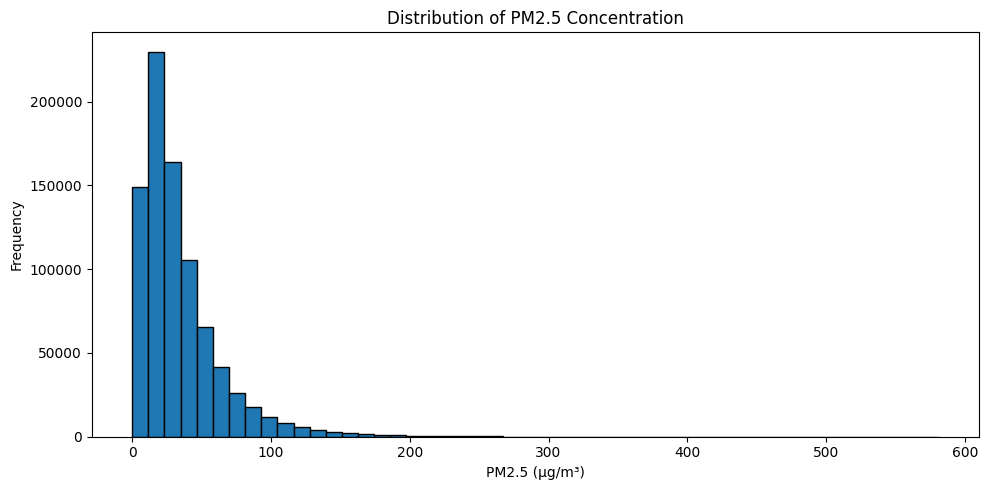

In [17]:
# ==========================================
#  HISTOGRAM - PM2.5
# ==========================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["PM2_5_ugm3"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of PM2.5 Concentration")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

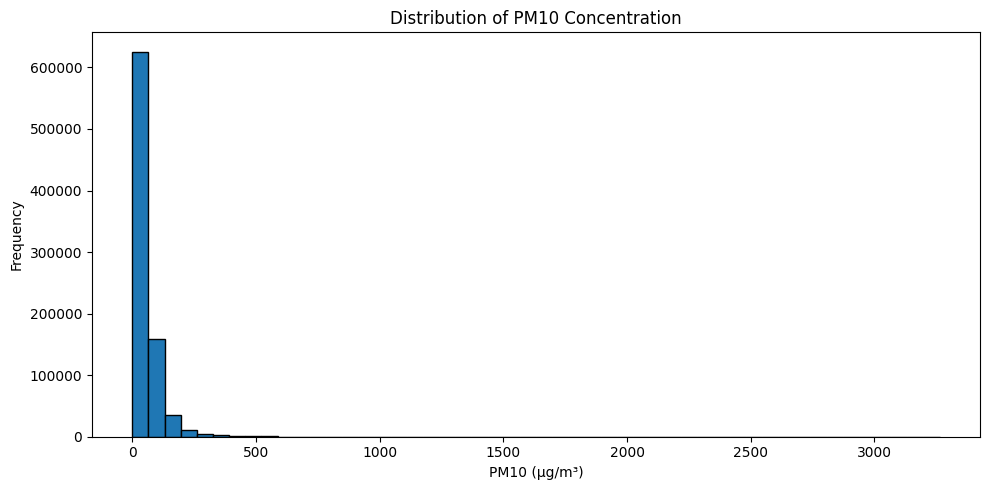

In [18]:
# ==========================================
#  HISTOGRAM - PM10
# ==========================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["PM10_ugm3"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of PM10 Concentration")
plt.xlabel("PM10 (µg/m³)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

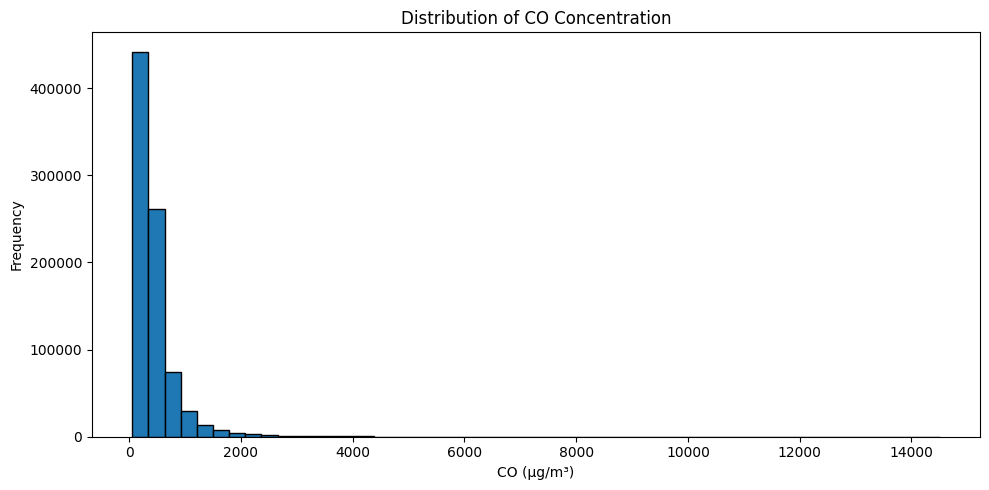

In [19]:
# ==========================================
#  HISTOGRAM - CO
# ==========================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["CO_ugm3"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of CO Concentration")
plt.xlabel("CO (µg/m³)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


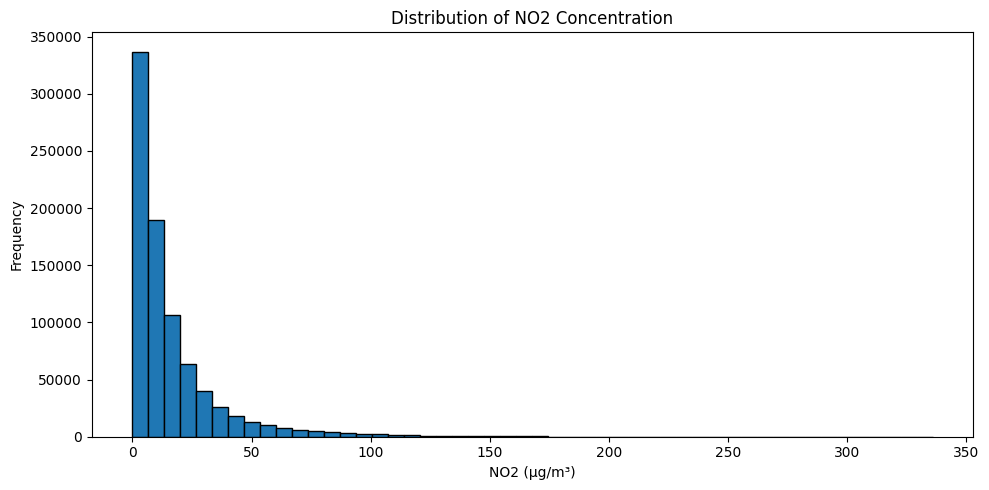

In [20]:
# ==========================================
#  HISTOGRAM - NO2
# ==========================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["NO2_ugm3"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of NO2 Concentration")
plt.xlabel("NO2 (µg/m³)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

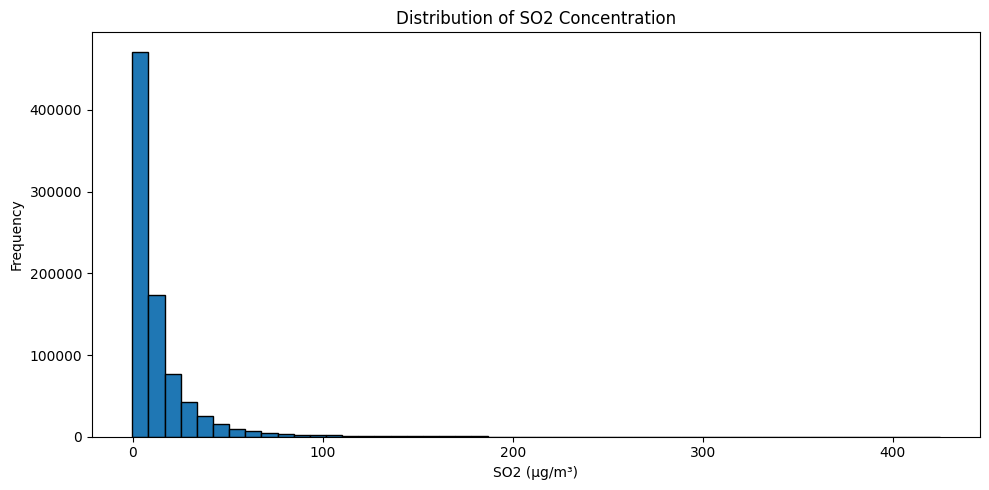

In [21]:
# ==========================================
#  HISTOGRAM - SO2
# ==========================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["SO2_ugm3"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of SO2 Concentration")
plt.xlabel("SO2 (µg/m³)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

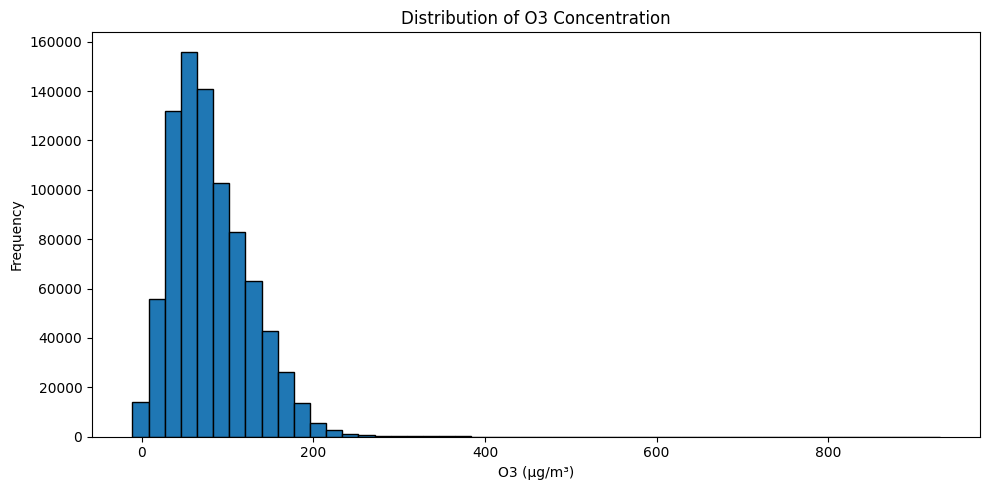

In [22]:
# ==========================================
#  HISTOGRAM - O3
# ==========================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["O3_ugm3"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of O3 Concentration")
plt.xlabel("O3 (µg/m³)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

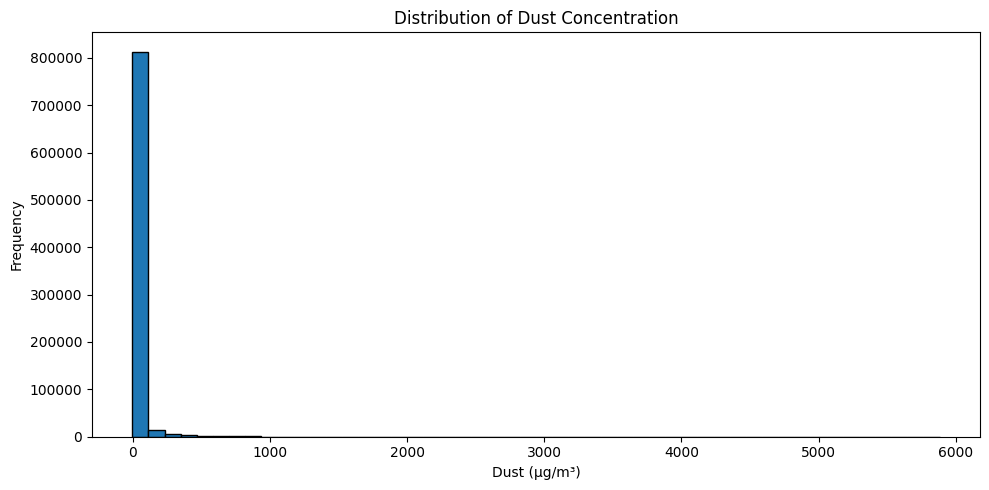

In [23]:
# ==========================================
#  HISTOGRAM - DUST
# ==========================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["Dust_ugm3"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Dust Concentration")
plt.xlabel("Dust (µg/m³)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

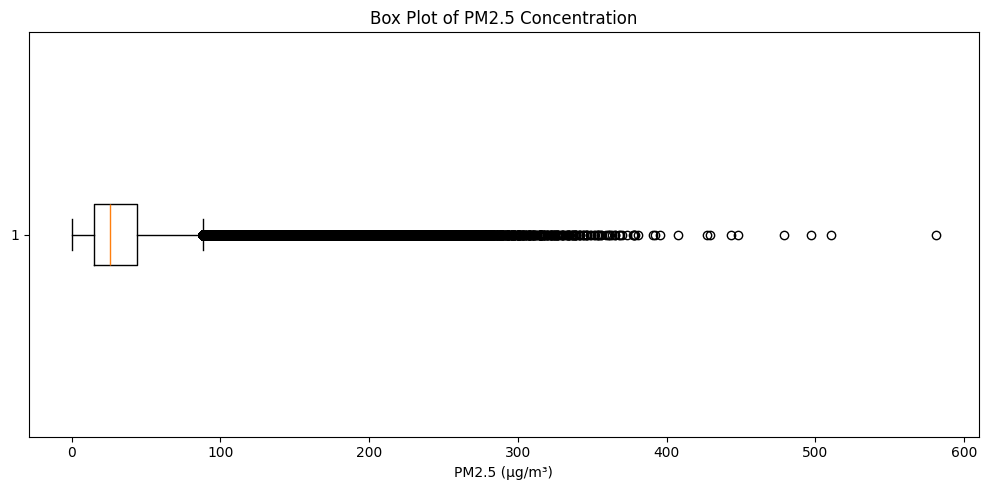

In [24]:
# ==========================================
#  BOX PLOT - PM2.5
# ==========================================

plt.figure(figsize=(10, 5))

plt.boxplot(
    df["PM2_5_ugm3"],
    vert=False
)

plt.title("Box Plot of PM2.5 Concentration")
plt.xlabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

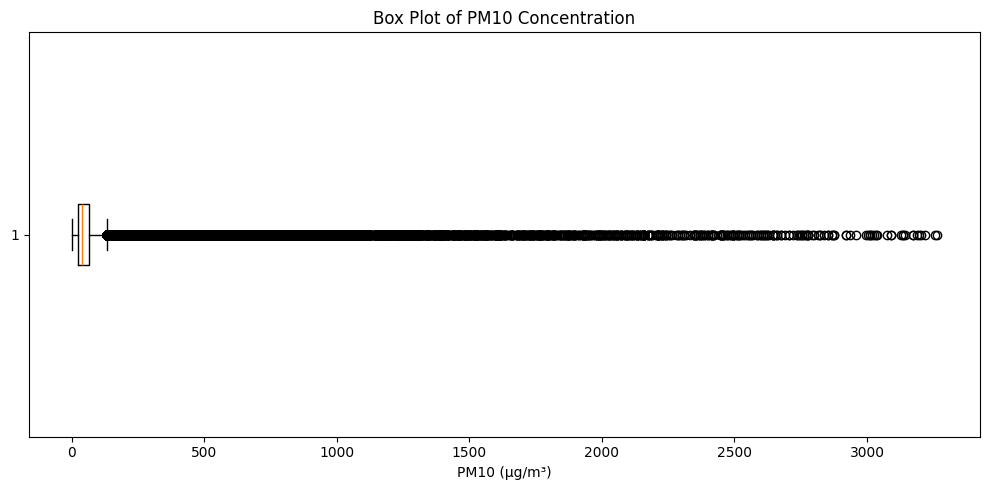

In [25]:
# ==========================================
#  BOX PLOT - PM10
# ==========================================

plt.figure(figsize=(10, 5))

plt.boxplot(
    df["PM10_ugm3"],
    vert=False
)

plt.title("Box Plot of PM10 Concentration")
plt.xlabel("PM10 (µg/m³)")

plt.tight_layout()
plt.show()

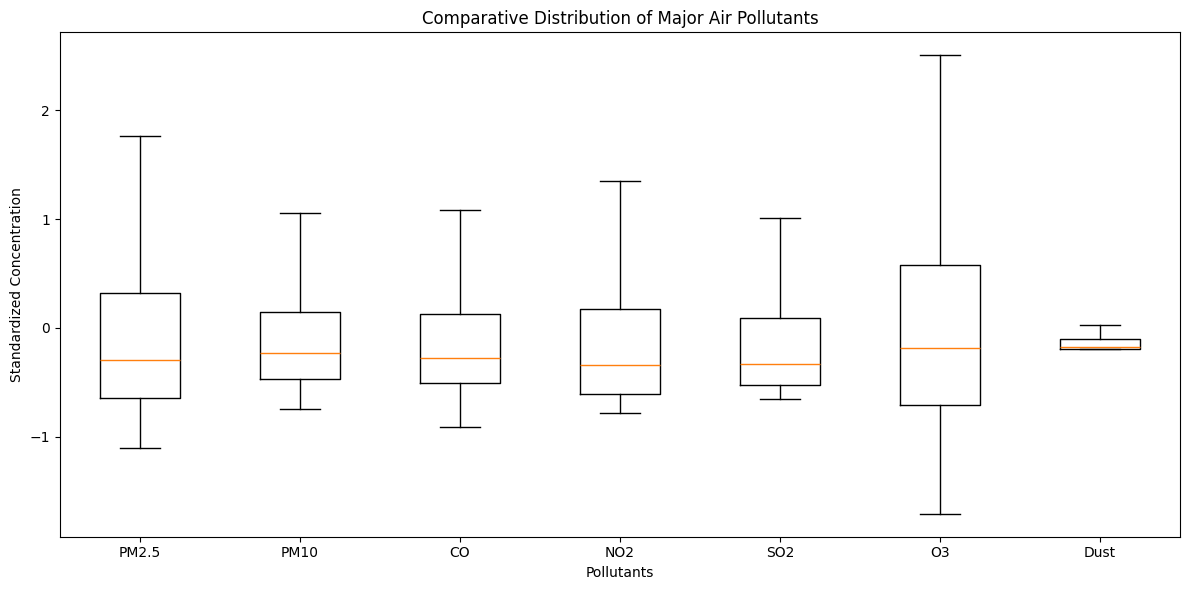

In [26]:
# ==========================================
#  COMPARATIVE BOX PLOT - POLLUTANTS
# ==========================================

pollutants = [
    "PM2_5_ugm3",
    "PM10_ugm3",
    "CO_ugm3",
    "NO2_ugm3",
    "SO2_ugm3",
    "O3_ugm3",
    "Dust_ugm3"
]

# Sample data for faster visualization
df_box = df[pollutants].sample(
    n=10000,
    random_state=42
)

# Standardize each pollutant
df_box_standardized = (
    df_box - df_box.mean()
) / df_box.std()

plt.figure(figsize=(12, 6))

plt.boxplot(
    [df_box_standardized[col].dropna() for col in pollutants],
    labels=["PM2.5", "PM10", "CO", "NO2", "SO2", "O3", "Dust"],
    showfliers=False
)

plt.title("Comparative Distribution of Major Air Pollutants")
plt.xlabel("Pollutants")
plt.ylabel("Standardized Concentration")

plt.tight_layout()
plt.show()

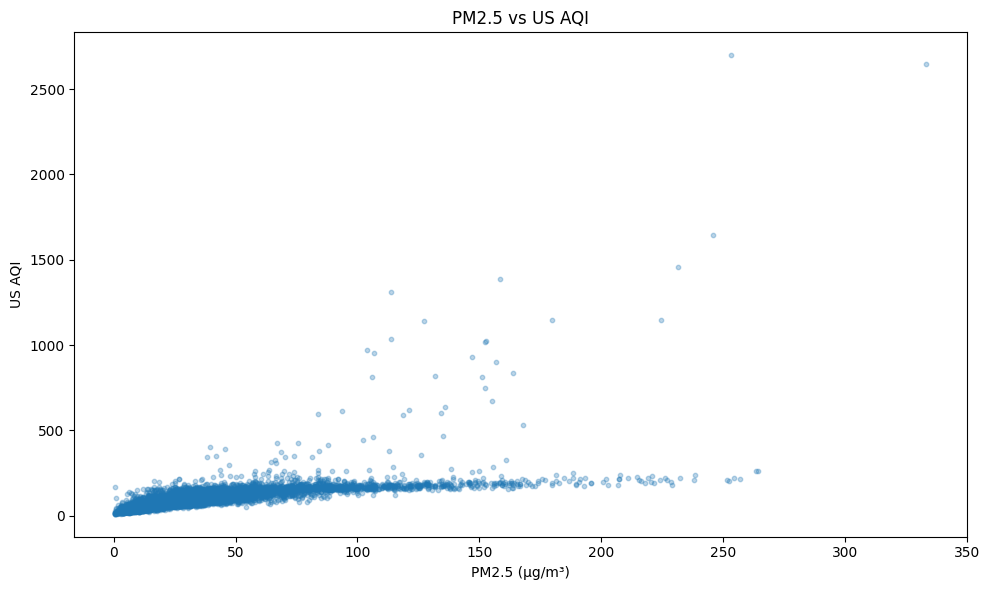

In [27]:
# ==========================================
#  SCATTER PLOT - PM2.5 vs US AQI
# ==========================================

df_scatter = df[
    ["PM2_5_ugm3", "US_AQI"]
].dropna().sample(
    n=10000,
    random_state=42
)

plt.figure(figsize=(10, 6))

plt.scatter(
    df_scatter["PM2_5_ugm3"],
    df_scatter["US_AQI"],
    alpha=0.3,
    s=10
)

plt.title("PM2.5 vs US AQI")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("US AQI")

plt.tight_layout()
plt.show()

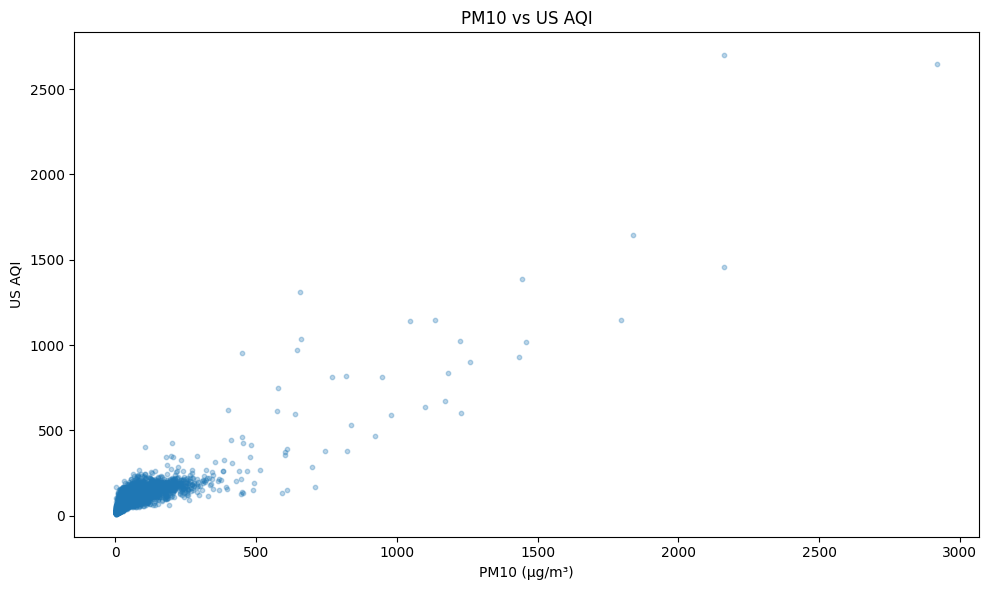

In [28]:
# ==========================================
#  SCATTER PLOT - PM10 vs US AQI
# ==========================================

df_scatter = df[
    ["PM10_ugm3", "US_AQI"]
].dropna().sample(
    n=10000,
    random_state=42
)

plt.figure(figsize=(10, 6))

plt.scatter(
    df_scatter["PM10_ugm3"],
    df_scatter["US_AQI"],
    alpha=0.3,
    s=10
)

plt.title("PM10 vs US AQI")
plt.xlabel("PM10 (µg/m³)")
plt.ylabel("US AQI")

plt.tight_layout()
plt.show()

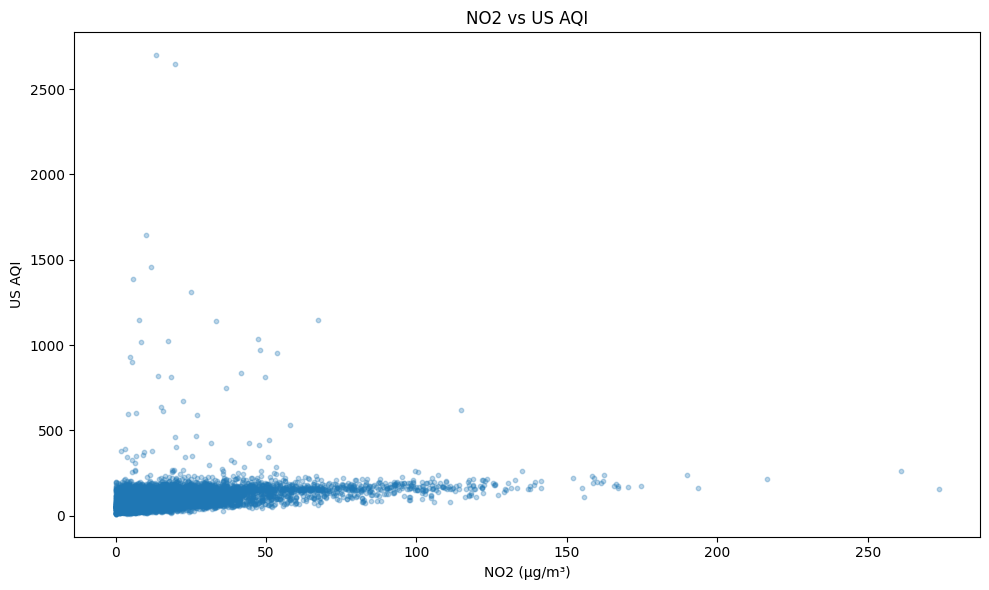

In [29]:
# ==========================================
#  SCATTER PLOT - NO2 vs US AQI
# ==========================================

df_scatter = df[
    ["NO2_ugm3", "US_AQI"]
].dropna().sample(
    n=10000,
    random_state=42
)

plt.figure(figsize=(10, 6))

plt.scatter(
    df_scatter["NO2_ugm3"],
    df_scatter["US_AQI"],
    alpha=0.3,
    s=10
)

plt.title("NO2 vs US AQI")
plt.xlabel("NO2 (µg/m³)")
plt.ylabel("US AQI")

plt.tight_layout()
plt.show()

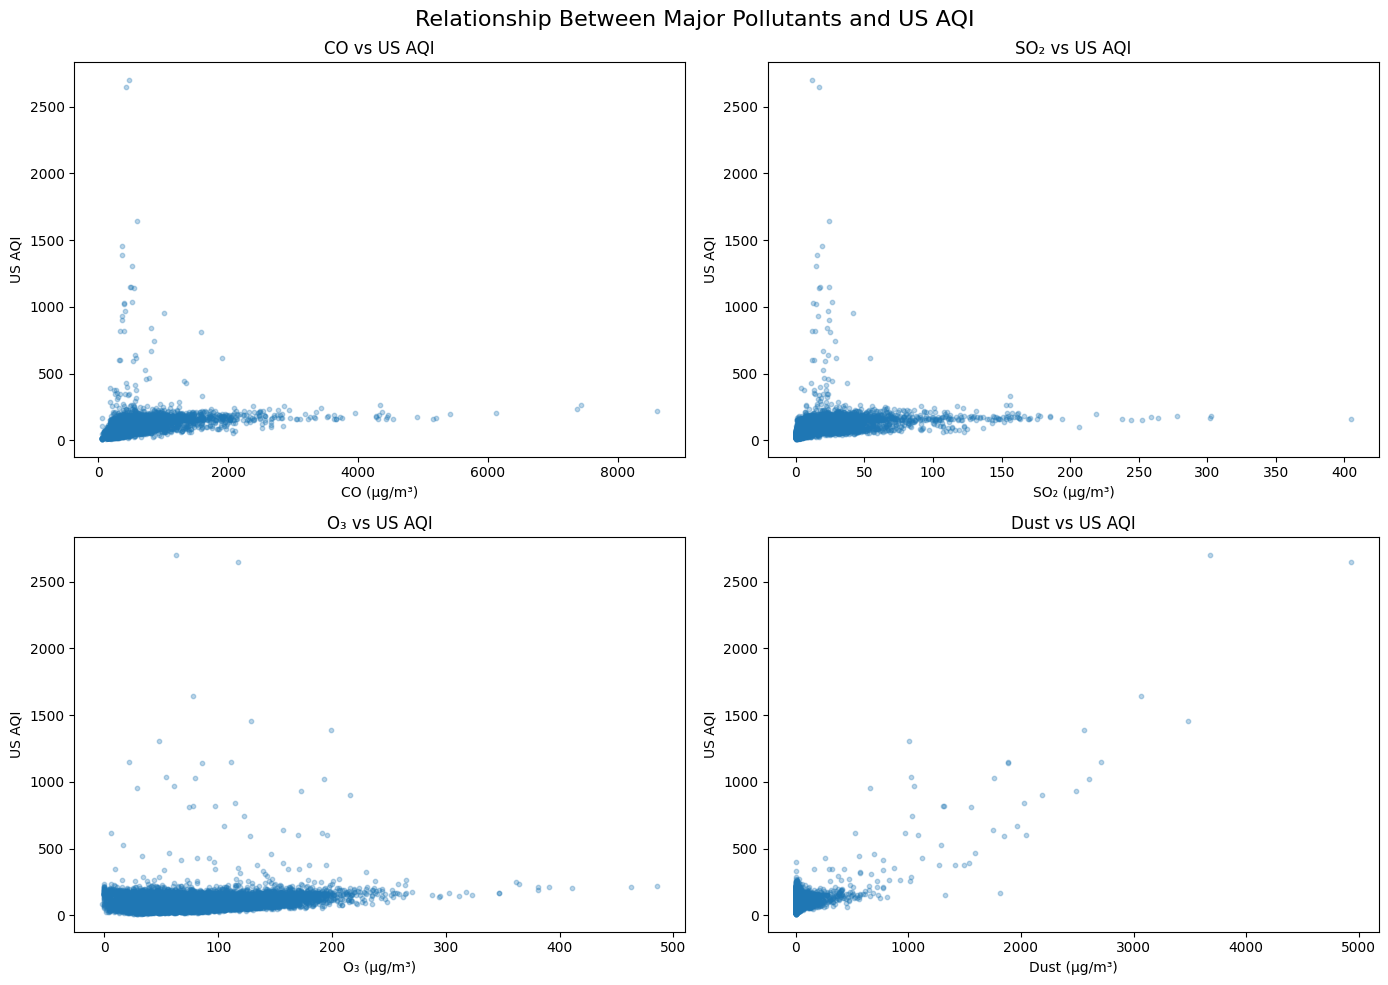

In [30]:
# ==========================================================
#  SCATTER PLOTS - OTHER POLLUTANTS vs US AQI
# ==========================================================

pollutants = {
    "CO_ugm3": "CO",
    "SO2_ugm3": "SO₂",
    "O3_ugm3": "O₃",
    "Dust_ugm3": "Dust"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (column, name) in zip(axes.flatten(), pollutants.items()):

    # Select required columns and remove missing values
    df_scatter = df[[column, "US_AQI"]].dropna()

    # Random sample for efficient visualization
    df_scatter = df_scatter.sample(
        n=10000,
        random_state=42
    )

    # Scatter plot
    ax.scatter(
        df_scatter[column],
        df_scatter["US_AQI"],
        alpha=0.3,
        s=10
    )

    ax.set_title(f"{name} vs US AQI")
    ax.set_xlabel(f"{name} (µg/m³)")
    ax.set_ylabel("US AQI")

plt.suptitle(
    "Relationship Between Major Pollutants and US AQI",
    fontsize=16
)

plt.tight_layout()
plt.show()

##  Scatter Plot Insights

The scatter plots were used to examine the relationship between major air pollutants and US AQI.

### Key Observations:

1. PM2.5 and PM10 show a generally positive association with US AQI, with higher particulate concentrations corresponding to several higher AQI observations.

2. The gaseous pollutants CO, NO2, SO2 and O3 also show varying degrees of association with US AQI, although the relationships are not perfectly linear.

3. High pollutant concentrations are associated with some of the highest observed AQI values, indicating the presence of potentially important high-pollution observations.

4. Considerable variation is visible in the scatter plots, suggesting that US AQI is not explained by a single pollutant alone.

5. The observed associations do not establish causation. Further quantitative analysis and machine-learning models are required to investigate pollutant–AQI relationships more systematically.

### Research Relevance:

The presence of high-concentration pollutant observations and high-AQI observations is particularly relevant to this study because the research focuses on evaluating machine-learning model robustness during extreme pollution conditions.

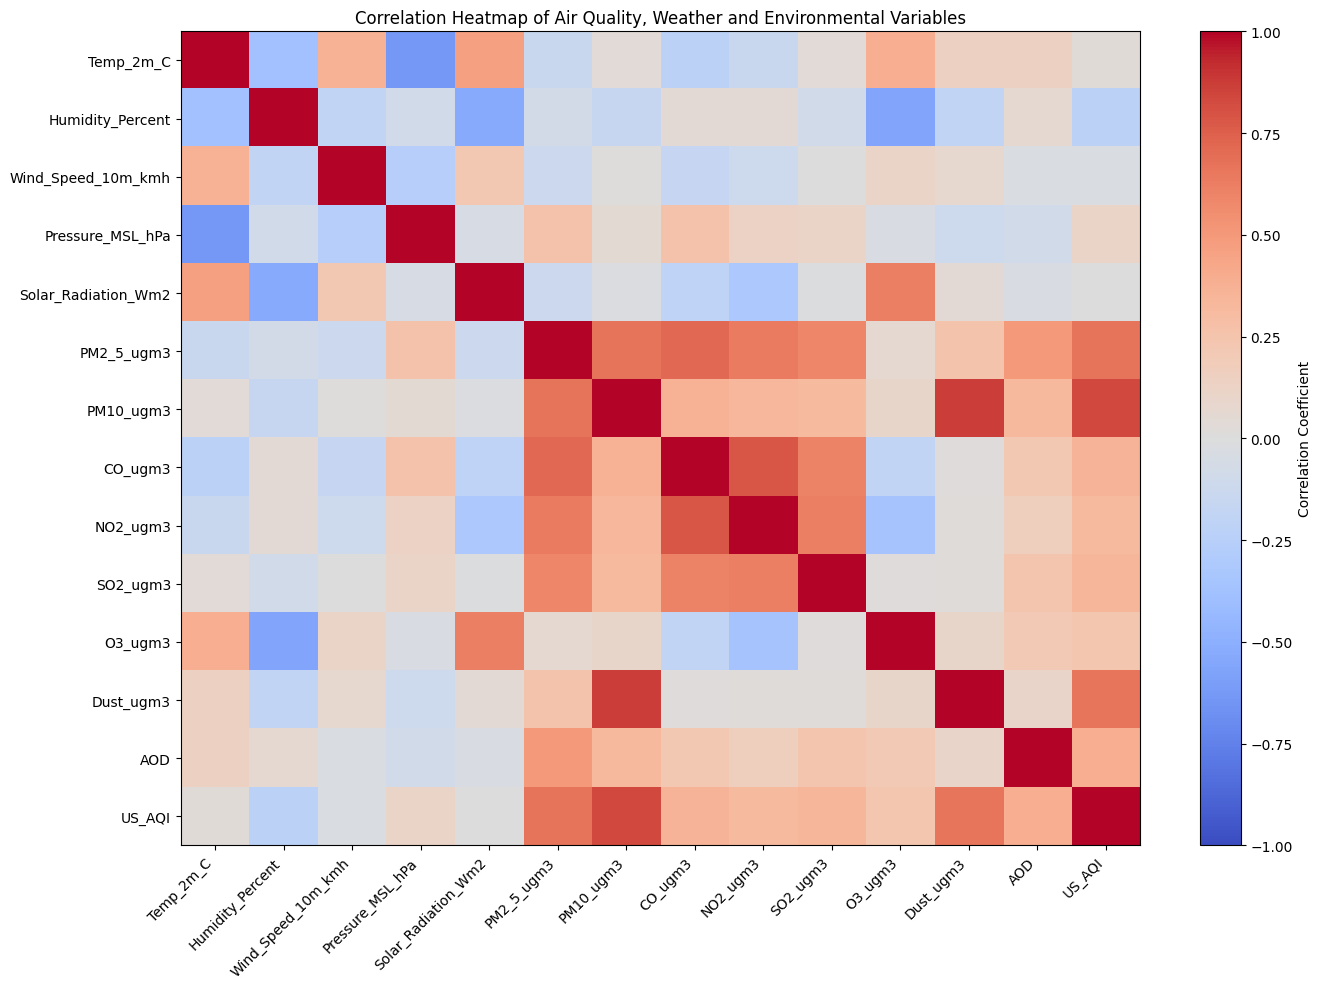

In [31]:
# ==========================================================
#  CORRELATION HEATMAP
# ==========================================================

correlation_columns = [
    "Temp_2m_C",
    "Humidity_Percent",
    "Wind_Speed_10m_kmh",
    "Pressure_MSL_hPa",
    "Solar_Radiation_Wm2",
    "PM2_5_ugm3",
    "PM10_ugm3",
    "CO_ugm3",
    "NO2_ugm3",
    "SO2_ugm3",
    "O3_ugm3",
    "Dust_ugm3",
    "AOD",
    "US_AQI"
]

# Calculate correlation matrix
corr_matrix = df[correlation_columns].corr()

# Plot heatmap
plt.figure(figsize=(14, 10))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title(
    "Correlation Heatmap of Air Quality, Weather and Environmental Variables"
)

plt.tight_layout()
plt.show()

In [32]:
# ==========================================
#  CORRELATION WITH US AQI
# ==========================================

aqi_correlation = (
    corr_matrix["US_AQI"]
    .drop("US_AQI")
    .sort_values(ascending=False)
)

print("Correlation of Variables with US AQI:")
print(aqi_correlation)

Correlation of Variables with US AQI:
PM10_ugm3              0.829666
PM2_5_ugm3             0.667822
Dust_ugm3              0.663002
AOD                    0.387045
CO_ugm3                0.354770
SO2_ugm3               0.339538
NO2_ugm3               0.314661
O3_ugm3                0.226693
Pressure_MSL_hPa       0.116554
Temp_2m_C              0.027512
Solar_Radiation_Wm2   -0.002959
Wind_Speed_10m_kmh    -0.026161
Humidity_Percent      -0.223264
Name: US_AQI, dtype: float64


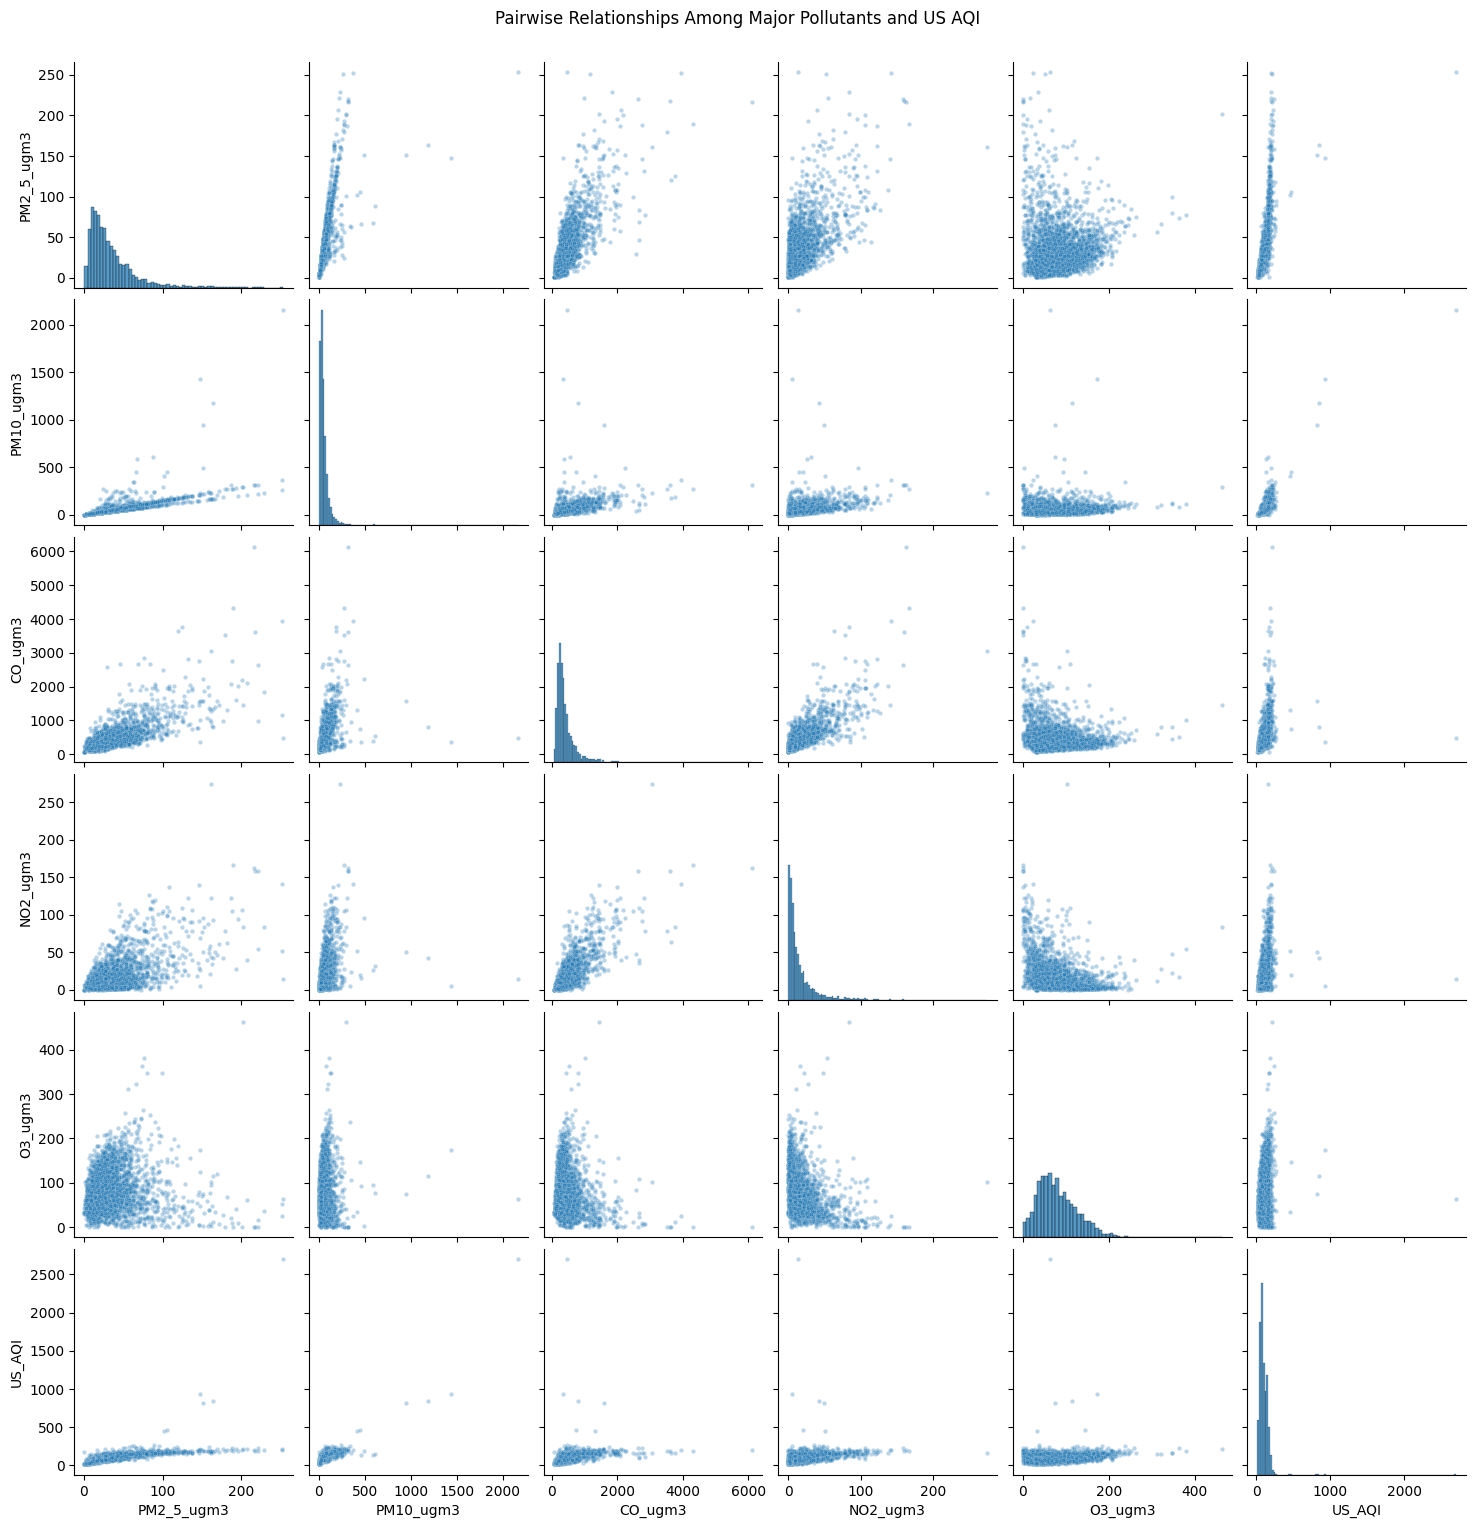

In [33]:
# ==========================================================
#  PAIRPLOT - MAJOR POLLUTANTS AND US AQI
# ==========================================================

pairplot_columns = [
    "PM2_5_ugm3",
    "PM10_ugm3",
    "CO_ugm3",
    "NO2_ugm3",
    "O3_ugm3",
    "US_AQI"
]

# Select required columns
df_pairplot = df[pairplot_columns].dropna()

# Random sample for efficient visualization
df_pairplot = df_pairplot.sample(
    n=3000,
    random_state=42
)

# Create pairplot
sns.pairplot(
    df_pairplot,
    diag_kind="hist",
    plot_kws={
        "alpha": 0.3,
        "s": 10
    }
)

plt.suptitle(
    "Pairwise Relationships Among Major Pollutants and US AQI",
    y=1.02
)

plt.show()

# EDA INSIGHTS

The exploratory data analysis of the Indian Air Quality dataset revealed several important patterns relevant to the study of machine-learning robustness during extreme pollution events.

### 1. Dataset Coverage
- The dataset contains 842,160 hourly observations.
- It covers 29 Indian cities across 29 states.
- The observations span the years 2022 to 2025.
- Each city contains approximately 29,040 observations, providing a balanced city-wise representation.

### 2. Missing Value Analysis
- Several meteorological variables such as Temp_80m_C, Temp_120m_C, Temp_180m_C, Wind_Speed_80m_kmh, Wind_Speed_120m_kmh, UV_Index, NH3_ugm3 and Inversion_Strength_C contain 100% missing values.
- These variables will require careful treatment during the machine-learning preprocessing stage and will not be blindly imputed.
- AQI-related variables contain only a very small proportion of missing observations.

### 3. Duplicate Analysis
- No duplicate rows were detected in the dataset.
- This indicates that the observations are unique at the complete-row level.

### 4. Temporal and Geographic Coverage
- The dataset contains observations from 29 cities and 29 states.
- Four seasons are represented: Monsoon, Summer, Winter and Post-Monsoon.
- Six time-of-day categories are present, allowing temporal pollution patterns to be investigated.

### 5. Pollutant Distribution
- PM2.5, PM10, CO, NO2, SO2 and Dust show strongly right-skewed distributions.
- Most observations occur at relatively lower concentration levels, while a smaller number of observations show very high pollutant concentrations.
- O3 shows a comparatively different distribution with a broader concentration range.

### 6. Outlier Analysis
- Box plots reveal a large number of high-value observations, particularly for PM2.5 and PM10.
- These observations should not automatically be removed because extreme pollution episodes are directly relevant to the research question.
- Instead, extreme observations will be retained and analyzed separately during the machine-learning stage.

### 7. Pollutant–AQI Relationships
- Scatter plots show generally positive associations between major pollutants and US AQI.
- PM10 and PM2.5 show particularly clear positive relationships with US AQI.
- High pollutant concentrations are associated with several of the highest AQI observations.

### 8. Correlation Analysis
- PM10 has the strongest positive correlation with US AQI among the selected variables, with a correlation coefficient of approximately 0.83.
- PM2.5 and Dust also show relatively strong positive correlations with US AQI, approximately 0.67 and 0.66 respectively.
- CO, SO2 and NO2 show moderate positive associations with US AQI.
- Humidity shows a negative correlation with US AQI, while temperature, wind speed and solar radiation show relatively weak linear correlations.

### 9. Research Relevance
The EDA indicates that the dataset contains both normal and unusually high pollution observations. The presence of extreme pollutant values and AQI observations provides a suitable basis for investigating whether machine-learning models maintain their predictive reliability during severe pollution episodes.

However, correlation and exploratory analysis alone cannot determine model reliability. Therefore, machine-learning models will be evaluated separately on normal and extreme pollution conditions.

#  EDA CONCLUSION

The exploratory data analysis provides a comprehensive understanding of the Indian air-quality dataset covering 29 Indian cities from 2022 to 2025.

The dataset contains 842,160 hourly observations and includes pollutant concentrations, meteorological conditions, temporal information and AQI-related variables. The analysis identified several completely missing variables as well as a small number of missing AQI observations, while no duplicate rows were detected.

The distribution analysis showed that several major pollutants, particularly PM2.5, PM10, CO, NO2, SO2 and Dust, have highly right-skewed distributions with substantial high-value observations. The box plots further confirmed the presence of extreme observations.

Correlation and scatter-plot analysis showed positive associations between several pollutants and US AQI. PM10 showed the strongest correlation with US AQI among the selected variables, followed by PM2.5 and Dust.

Most importantly, the EDA confirms that the dataset contains a substantial range of pollution conditions, including high-concentration observations. This makes the dataset suitable for the next stage of the study, where multiple machine-learning models will be trained and evaluated under both normal and extreme pollution conditions.

The machine-learning stage will therefore focus not only on overall predictive performance but also on whether model performance changes when the air-quality conditions become severe.